# RAG Assignment: Baseline Retrieval vs. Cross-Encoder Re-Ranking

**Document:** NIST Special Publication 800-63B-4, *Digital Identity Guidelines: Authentication and Authenticator Management* (July 2025, 129 pages):
the US standard for passwords, multi-factor authentication, OTPs, passkeys, biometrics and session management.
**Author:** MD TAUFIQUE HUSSAIN (Roll No. 2025202007)

This notebook builds **two retrieval pipelines over the exact same chunked corpus** and compares them:

```
                    ┌──────────────────────────────── Pipeline 1 (Baseline) ───────────────────────────────┐
 query ─► Bi-Encoder ─► cosine search over all chunks ─► Top 10 ─► take Top 3 as-is ─► LLM ─► Answer 1
                                                            │
                    ┌───────────────────────────────────────┴──── Pipeline 2 (Re-Ranking) ───────────────┐
                    └─► score all 10 (query, chunk) pairs with Cross-Encoder ─► re-sort ─► Top 3 ─► LLM ─► Answer 2
```

Both pipelines use the **same chunks, the same Top-10 candidate list, the same LLM and the identical prompt template**.
The only difference is *which 3 chunks* reach the LLM, so any difference between Answer 1 and Answer 2 is caused by re-ranking alone.

### Contents
1. Setup & environment (models, configuration)
2. Load and clean the PDF
3. Chunking
4. Pipeline building blocks: Bi-Encoder index, Cross-Encoder, LLM + prompt
5. Pipeline 1 and Pipeline 2
6. Sanity check on an easy query
7. **Failure-mode analysis (stress testing)**: exceptions, negation, keyword traps, synonyms, plus honest counter-examples
8. Rank-shift summary (table + chart)
9. Retrieval quality over a wider query set (Hit@3, MRR) and a chunk-size robustness check
10. **Latency profiling** and the **scaling** experiment (Cross-Encoder over the whole corpus)
11. Where to find the evidence for each report question

## 1. Setup & Environment

| Component | Choice | Why |
|---|---|---|
| Document | NIST SP 800-63B-4 (PDF, 129 pages, ~37k words after cleaning) | A dense technical standard. Its rules are written as `SHALL` / `SHALL NOT` / `SHOULD NOT` (negation), are full of exceptions ("…unless…", "However, …"), and repeat almost the same sentences for the three Authentication Assurance Levels (AAL1/2/3) with different numbers. Ideal for stressing retrieval. |
| Bi-Encoder (dense retriever) | `sentence-transformers/all-MiniLM-L6-v2` | Standard, small (22M params) embedding model; query and chunk are embedded **independently**. |
| Vector store | FAISS `IndexFlatIP` on L2-normalised vectors | Inner product of unit vectors = **cosine similarity**; exact (brute-force) search, so the baseline is not weakened by approximate search. |
| Cross-Encoder (re-ranker) | `cross-encoder/ms-marco-MiniLM-L-6-v2` | The model suggested in the assignment; reads query and chunk **together**. |
| LLM | Local open-weights `Qwen/Qwen2.5-1.5B-Instruct` via Hugging Face (default), or Gemini API if `GEMINI_API_KEY` is set | Runs on a laptop CPU with no API key. Greedy decoding → deterministic, reproducible answers. |

**How to run:** `pip install -r requirements.txt`, then *Run All*. The PDF is downloaded automatically if `data/NIST_SP_800-63B-4.pdf` is missing.
Models are downloaded from Hugging Face on first run.

**Vocabulary used below:** *AAL* = Authentication Assurance Level (1 = lowest, 3 = highest); *CSP* = credential service provider;
*verifier* = the system that checks a login; *out-of-band (OOB)* = a code sent to a second device (e.g. by SMS); *PSTN* = the public telephone network (SMS/voice);
*syncable authenticator* = a passkey that is synced between devices through the cloud.

In [1]:
# On a fresh machine or Colab, remove the # in the next line to install the packages.
# !pip install -q sentence-transformers transformers accelerate faiss-cpu pypdf pandas matplotlib google-genai

In [2]:
import os, re, time, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import faiss
from pypdf import PdfReader
from sentence_transformers import SentenceTransformer, CrossEncoder
from IPython.display import display, Markdown

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)

# ----------------------------- settings you can change -----------------------------
PDF_PATH = Path("data/NIST_SP_800-63B-4.pdf")
PDF_URL  = "https://nvlpubs.nist.gov/nistpubs/SpecialPublications/NIST.SP.800-63B-4.pdf"

CHUNK_WORDS   = 120   # words in one chunk (about one rule paragraph)
CHUNK_OVERLAP = 30    # words shared by two neighbouring chunks, so a rule cut at the end of one chunk is still complete in the next

TOP_K_RETRIEVE = 10   # number of chunks the Bi-Encoder returns (both pipelines start from these)
TOP_K_CONTEXT  = 3    # number of chunks sent to the LLM

BI_ENCODER_NAME    = "sentence-transformers/all-MiniLM-L6-v2"
CROSS_ENCODER_NAME = "cross-encoder/ms-marco-MiniLM-L-6-v2"

# The notebook uses Gemini if an API key is set, otherwise a local model.
GEMINI_MODEL = "gemini-2.5-flash"
LOCAL_LLM    = "Qwen/Qwen2.5-1.5B-Instruct"
MAX_NEW_TOKENS = 160

RESULTS_DIR = Path("results"); RESULTS_DIR.mkdir(exist_ok=True)

torch.manual_seed(0); np.random.seed(0)
print("torch", torch.__version__, "| CPU threads:", torch.get_num_threads(), "| CUDA:", torch.cuda.is_available())

torch 2.14.1+cpu | CPU threads: 6 | CUDA: False


## 2. Load and clean the PDF

We extract the text page by page with `pypdf` and apply two cleaning steps before chunking:

1. **Skip the front matter** (title pages, legal notices, a 4-page table of contents, preface). The body starts at "1. Introduction".
   The table of contents lists every section title, so it would match almost any query while containing no answer,
   which would be an artificial distractor.
2. **Remove the running header and page number** that NIST prints on every page (`NIST SP 800-63B-4 / July 2025 / Digital Identity Guidelines / …`).
   Otherwise every chunk would share these words.

We also remember the PDF page every word came from, so each chunk can be traced back to its page.

In [3]:
if not PDF_PATH.exists():                      # download the PDF once (the NIST server needs a browser like User-Agent)
    PDF_PATH.parent.mkdir(parents=True, exist_ok=True)
    req = urllib.request.Request(PDF_URL, headers={"User-Agent": "Mozilla/5.0"})
    PDF_PATH.write_bytes(urllib.request.urlopen(req).read())

raw_pages = [page.extract_text() or "" for page in PdfReader(PDF_PATH).pages]
HEADER_LINES = {"NIST SP 800-63B-4", "July 2025", "Digital Identity Guidelines", "Authentication and Authenticator Management"}

# 1) skip the first pages (title, notices, contents); the real text starts at "1. Introduction"
body_start = next(i for i, t in enumerate(raw_pages) if "1. Introduction\nThis section is informative." in t)

words, word_page = [], []                      # every word of the cleaned text, and the PDF page of each word
for page_no in range(body_start, len(raw_pages)):
    lines = [l for l in raw_pages[page_no].split("\n") if l.strip() not in HEADER_LINES]   # 2) remove the header printed on every page
    if lines and re.fullmatch(r"\s*\d+\s*", lines[-1]):                                    #    remove the page number
        lines = lines[:-1]
    page_words = re.sub(r"\s+", " ", " ".join(lines)).strip().split(" ")
    words.extend(page_words)
    word_page.extend([page_no + 1] * len(page_words))

print(f"PDF pages: {len(raw_pages)} | front-matter pages skipped: {body_start} | words kept: {len(words):,}")
print("First 60 words of the body:", " ".join(words[:60]), "...")

PDF pages: 129 | front-matter pages skipped: 11 | words kept: 37,120
First 60 words of the body: 1. Introduction This section is informative. Authentication is the process of determining the validity of one or more authenticators used to claim a digital identity by establishing that a subject attempting to access a digital service is in control of the secrets used to authenticate. If return visits are applicable to a service, successful authentication provides reasonable risk-based assurance that ...


## 3. Chunking

A **sliding window** of `CHUNK_WORDS` words that moves forward by `CHUNK_WORDS - CHUNK_OVERLAP` words.
This one list of chunks is the corpus used by **both** pipelines; nothing is re-chunked later.

*Design note:* a 120-word chunk holds roughly one requirement paragraph. Each chunk is focused, which helps retrieval,
but a general rule and its exception ("SHALL NOT … However, … SHALL …") or the AAL1, AAL2 and AAL3 versions of a rule often end up in **different** chunks.
That is the situation the assignment asks us to stress-test. §9.1 checks that the conclusions also hold for other chunk sizes.

In [4]:
def make_chunks(words, word_page, size, overlap):
    # Cut the word list into overlapping chunks and return a table with one row per chunk.
    step, rows = size - overlap, []
    for start in range(0, len(words), step):
        piece = words[start:start + size]
        if len(piece) < 20 and rows:           # skip a very short last piece (its words are already in the previous chunk)
            break
        rows.append({"chunk_id": len(rows), "page": word_page[start], "n_words": len(piece), "text": " ".join(piece)})
    return pd.DataFrame(rows)

chunks_df = make_chunks(words, word_page, CHUNK_WORDS, CHUNK_OVERLAP)
chunks = chunks_df["text"].tolist()

print(f"{len(chunks)} chunks of ≤{CHUNK_WORDS} words (overlap {CHUNK_OVERLAP})")
display(chunks_df.head(5))

413 chunks of ≤120 words (overlap 30)


,chunk_id,page,n_words,text
0,0,12,120,1. Introduction This section is informative. Authentication is the process of determin...
1,1,12,120,not necessarily require persistent digital authentication nor the issuance of authenti...
2,2,12,120,"authentication — of an identity provider (IdP). Upon successful authentication, the ve..."
3,3,12,120,to the digital authentication of subjects to systems over a network. It also requires ...
4,4,12,120,not intended to protect against willful disclosure of credential secrets by a subscrib...


## 4. Building blocks

### 4.1 Bi-Encoder + vector store (used by Pipeline 1, and as the first stage of Pipeline 2)

Every chunk is embedded **once, offline**, into a 384-dimensional vector. The vectors are L2-normalised,
so the FAISS inner product equals **cosine similarity**. At query time only the *query* has to be embedded.

In [5]:
bi_encoder = SentenceTransformer(BI_ENCODER_NAME)

t0 = time.perf_counter()
chunk_emb = bi_encoder.encode(chunks, normalize_embeddings=True, convert_to_numpy=True, batch_size=32).astype("float32")
index_build_s = time.perf_counter() - t0

index = faiss.IndexFlatIP(chunk_emb.shape[1])  # exact search (no approximation)
index.add(chunk_emb)
print(f"Indexed {index.ntotal} chunks, dim={chunk_emb.shape[1]}, offline embedding time = {index_build_s:.2f} s (one-time cost)")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 4671.22it/s]

Indexed 413 chunks, dim=384, offline embedding time = 13.46 s (one-time cost)


### 4.2 Cross-Encoder (used only by Pipeline 2)

The Cross-Encoder takes a **(query, chunk) pair as one input sequence** and outputs a single relevance score (a logit;
higher = more relevant). Nothing can be pre-computed: it has to run once per pair, at query time.

In [6]:
cross_encoder = CrossEncoder(CROSS_ENCODER_NAME)
print("Example score (relevant pair):  ", cross_encoder.predict([("What is the minimum password length?", "Verifiers SHALL require passwords to be a minimum of 15 characters in length.")])[0])
print("Example score (irrelevant pair):", cross_encoder.predict([("What is the minimum password length?", "The biometric system SHALL implement PAD for facial recognition.")])[0])

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 10036.96it/s]

Example score (relevant pair):   6.672948
Example score (irrelevant pair): -11.417233


### 4.3 LLM and the (identical) prompt template

Both answers are generated by **the same function with the same template**; only the three context chunks differ.
The prompt tells the model to answer *only* from the passages (and to say "Not found in the provided passages." otherwise), so missing context
should show up as a refusal or a wrong answer rather than an answer from the model's own memory.

In [7]:
PROMPT_TEMPLATE = """You are an expert in digital identity and authentication security. Below are numbered passages from NIST Special Publication 800-63B-4 (a passage may start or end in the middle of a sentence).
Answer the question using only the information in these passages, and mention the section number if it is visible.
If none of the passages answers the question, reply: "Not found in the provided passages."
Answer in at most 3 sentences.

Passages:
{context}

Question: {question}
Answer:"""

def build_prompt(question, context_chunk_ids):
    # Put the chosen chunks into the prompt as numbered passages.
    context = "\n\n".join(f"[Passage {i+1}] {chunks[cid]}" for i, cid in enumerate(context_chunk_ids))
    return PROMPT_TEMPLATE.format(context=context, question=question)

GEMINI_KEY = os.environ.get("GEMINI_API_KEY") or os.environ.get("GOOGLE_API_KEY")

if GEMINI_KEY:                                         # ---- option A: use the Gemini API ----
    from google import genai
    from google.genai import types
    gemini = genai.Client(api_key=GEMINI_KEY)
    LLM_NAME = GEMINI_MODEL
    def llm_generate(prompt):
        resp = gemini.models.generate_content(model=GEMINI_MODEL, contents=prompt,
                                              config=types.GenerateContentConfig(temperature=0.0, max_output_tokens=MAX_NEW_TOKENS))
        return resp.text.strip()
else:                                                  # ---- option B: use a local model ----
    from transformers import AutoTokenizer, AutoModelForCausalLM
    tokenizer = AutoTokenizer.from_pretrained(LOCAL_LLM)
    llm = AutoModelForCausalLM.from_pretrained(
        LOCAL_LLM, dtype=torch.float16 if torch.cuda.is_available() else torch.bfloat16, low_cpu_mem_usage=True)
    llm.to("cuda" if torch.cuda.is_available() else "cpu").eval()
    LLM_NAME = LOCAL_LLM
    def llm_generate(prompt):
        inputs = tokenizer.apply_chat_template([{"role": "user", "content": prompt}], add_generation_prompt=True,
                                               return_tensors="pt", return_dict=True).to(llm.device)
        with torch.no_grad():
            out = llm.generate(**inputs, max_new_tokens=MAX_NEW_TOKENS, do_sample=False)   # no randomness, so every run gives the same answer
        return tokenizer.decode(out[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

print("LLM backend:", LLM_NAME)

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 338/338 [00:00<00:00, 3488.13it/s]

LLM backend: Qwen/Qwen2.5-1.5B-Instruct


## 5. The two pipelines

* **Pipeline 1 (Baseline):** embed query → cosine search → Top 10 → take ranks 1-3 → LLM → **Answer 1**
* **Pipeline 2 (Re-Ranking):** the *same* Top 10 → Cross-Encoder scores all 10 (query, chunk) pairs → sort descending → new Top 3 → LLM → **Answer 2**

Each step is timed separately with `time.perf_counter()`.

In [8]:
def baseline_retrieve(query, k=TOP_K_RETRIEVE):
    # Pipeline 1: encode the question and find the 10 most similar chunks. Returns ids, scores and time taken.
    t0 = time.perf_counter()
    q = bi_encoder.encode([query], normalize_embeddings=True, convert_to_numpy=True).astype("float32")
    scores, ids = index.search(q, k)
    return ids[0].tolist(), scores[0].tolist(), time.perf_counter() - t0

def cross_encoder_rerank(query, candidate_ids):
    # Pipeline 2: score each (question, chunk) pair with the Cross-Encoder and sort from best to worst. Returns ids, scores and time taken.
    t0 = time.perf_counter()
    ce_scores = cross_encoder.predict([(query, chunks[c]) for c in candidate_ids])
    order = np.argsort(-ce_scores)
    return [candidate_ids[i] for i in order], [float(ce_scores[i]) for i in order], time.perf_counter() - t0

def run_both(query, generate=True):
    # Run both pipelines on one question using the same top 10 chunks. Also writes Answer 1 and Answer 2 if asked.
    top10, cos, t_retrieve = baseline_retrieve(query)
    reranked, ce, t_rerank = cross_encoder_rerank(query, top10)
    r = {"query": query, "top10": top10, "cos": dict(zip(top10, cos)), "reranked": reranked, "ce": dict(zip(reranked, ce)),
         "t_retrieve": t_retrieve, "t_rerank": t_rerank,
         "ctx1": top10[:TOP_K_CONTEXT], "ctx2": reranked[:TOP_K_CONTEXT]}
    if generate:
        t0 = time.perf_counter(); r["answer1"] = llm_generate(build_prompt(query, r["ctx1"])); r["t_llm1"] = time.perf_counter() - t0
        t0 = time.perf_counter(); r["answer2"] = llm_generate(build_prompt(query, r["ctx2"])); r["t_llm2"] = time.perf_counter() - t0
    return r

### Helpers to *show* what happened

* A chunk is marked **gold (★)** if it contains the exact sentence of the standard that answers the question
  (we give that sentence as `gold_phrase`). This makes "was the right chunk retrieved?" an objective check rather than an opinion.
* `rank_shift_table` lists all 10 candidates with their rank and score under both pipelines.

In [9]:
def norm(s):
    # Make text lower case and fix quotes and spaces, so the gold sentence can be found inside a chunk.
    return re.sub(r"\s+", " ", s.lower().replace("’", "'").replace("‘", "'").replace("“", '"').replace("”", '"'))

def gold_chunks(gold_phrases):
    phrases = [gold_phrases] if isinstance(gold_phrases, str) else gold_phrases
    ids = [i for i, c in enumerate(chunks) if any(norm(p) in norm(c) for p in phrases)]
    assert ids, f"gold phrase not found in any chunk: {phrases}"
    return ids

def best_rank(order, golds):
    # Rank (starting from 1) of the best placed gold chunk, or None if no gold chunk is in the list.
    ranks = [i + 1 for i, c in enumerate(order) if c in golds]
    return min(ranks) if ranks else None

def rank_shift_table(r, golds):
    rows = []
    for b_rank, cid in enumerate(r["top10"], start=1):
        n_rank = r["reranked"].index(cid) + 1
        rows.append({"chunk": cid, "page": chunks_df.page[cid], "gold": "★" if cid in golds else "",
                     "baseline_rank": b_rank, "cosine": round(r["cos"][cid], 3),
                     "rerank_rank": n_rank, "cross_enc_score": round(r["ce"][cid], 2),
                     "shift": f"#{b_rank} → #{n_rank}" + ("  ▲" if n_rank < b_rank else "  ▼" if n_rank > b_rank else ""),
                     "in_LLM_context": ("P1 " if b_rank <= TOP_K_CONTEXT else "") + ("P2" if n_rank <= TOP_K_CONTEXT else ""),
                     "preview": chunks[cid][:85] + "…"})
    return pd.DataFrame(rows).set_index("chunk")

def fmt_rank(x):
    return f"#{x}" if x else "not in Top-10"

## 6. Sanity check: an easy query

When the query wording matches the standard's wording, both pipelines should agree. This confirms the setup works before stress-testing it.

In [10]:
easy = run_both("Should session cookies be readable by JavaScript?")
display(rank_shift_table(easy, gold_chunks("HttpOnly")).head(5))
display(Markdown(f"**Answer 1 (baseline):** {easy['answer1']}\n\n**Answer 2 (re-ranked):** {easy['answer2']}"))

,page,gold,baseline_rank,cosine,rerank_rank,cross_enc_score,shift,in_LLM_context,preview
chunk,,,,,,,,,
214,66,★,1,0.621,1,5.55,#1 → #1,P1 P2,Browser Cookies Browser cookies are the predominant mechanism by which a session is c…
213,65,,2,0.478,2,-0.07,#2 → #2,P1 P2,request forgery (CSRF). Several mechanisms exist for managing a session over time. Th…
212,65,,3,0.469,6,-2.52,#3 → #6 ▼,P1,"and the subscriber’s endpoint. In addition, the secrets used for session binding SHOU…"
244,76,,4,0.451,10,-6.85,#4 → #10 ▼,,essential that one authentication factor cannot be leveraged to obtain an authenticat…
412,129,,5,0.440,7,-4.13,#5 → #7 ▼,,cookies used for session maintenance • Section 5.2: Revises reauthentication requirem…


**Answer 1 (baseline):** Yes, according to Passage 1, session cookies should be tagged as inaccessible via JavaScript (i.e., HttpOnly).

**Answer 2 (re-ranked):** Yes, according to Passage 1, session cookies should be tagged as inaccessible via JavaScript (i.e., HttpOnly).

## 7. Failure-mode analysis (stress testing)

**Method.** For each query we identify the sentence of the standard that answers it (`gold_phrase`)
and write down the correct answer with its section number (`expected`). We then report:

1. the **rank of the gold chunk** in Pipeline 1 vs Pipeline 2 (e.g. *#10 → #1*),
2. the full Top-10 **rank-shift table**,
3. **Answer 1 vs Answer 2**, side by side with the expected answer from the standard.

The queries cover every category the assignment lists:

| # | Category | Query |
|---|---|---|
| 1 | Exceptions & corner cases | When must a user be forced to change their password? |
| 2 | Exceptions & corner cases | Is encryption required for one-time codes sent by SMS? |
| 3 | Exceptions & corner cases (level-specific restriction) | Can passkeys that sync across devices be used at AAL3? |
| 4 | Negation & constraints | Do users have to change their passwords every 90 days? |
| 5 | Negation & constraints | Does sending a new OTP reset the failed attempt counter? |
| 6 | Keyword trap / distractor (near-duplicate AAL rules) | What is the reauthentication timeout at AAL1? |
| 7 | Keyword trap / distractor (near-duplicate AAL rules) | What is the inactivity timeout at AAL3? |
| 8 | Other: synonym / buried chunk | Is the use of SMS for authentication restricted? |
| 9-11 | **Counter-examples** (where re-ranking does *not* help) | see §7.9 |

In [11]:
FAILURE_CASES = [
    dict(category="Exceptions & corner cases",
         query="When must a user be forced to change their password?",
         gold_phrase="force a change if there is evidence",
         expected="Sec. 3.1.1.2 (6): periodic password changes SHALL NOT be required, EXCEPT that verifiers SHALL force a change if there is evidence that the authenticator (password) has been compromised.",
         trap="Many chunks discuss changing or resetting passwords and authenticators (account recovery, binding new authenticators). The answer is a 'However…' exception inside the password-verifier list."),
    dict(category="Exceptions & corner cases",
         query="Is encryption required for one-time codes sent by SMS?",
         gold_phrase="unless sent via the public switched telephone network",
         expected="Sec. 3.1.3.1: communication over the secondary (out-of-band) channel SHALL use approved encryption UNLESS it is sent via the PSTN (SMS or voice). SMS codes are therefore the exception, and that is one reason PSTN is a restricted authenticator.",
         trap="'Encryption', 'SMS' and 'one-time code' each appear in many chunks (OTP devices, approved cryptography, PSTN restrictions). The exception uses the term 'PSTN' rather than 'SMS'."),
    dict(category="Exceptions & corner cases",
         query="Can passkeys that sync across devices be used at AAL3?",
         gold_phrase="syncable authenticators SHALL NOT be used at AAL3",
         expected="Sec. 2.3.2: no. AAL3 requires non-exportable keys; syncable authenticators require exportable private keys, so they SHALL NOT be used at AAL3 (they are allowed up to AAL2, Appendix B).",
         trap="Appendix B is entirely about syncable authenticators and describes how they satisfy AAL2. Those chunks look most similar, but the AAL3 prohibition is one sentence in Sec. 2.3.2."),
    dict(category="Negation & constraints",
         query="Do users have to change their passwords every 90 days?",
         gold_phrase="SHALL NOT require subscribers to change passwords periodically",
         expected="Sec. 3.1.1.2 (6): no. Verifiers and CSPs SHALL NOT require subscribers to change passwords periodically (only on evidence of compromise).",
         trap="The answer is a prohibition (SHALL NOT). The Bi-Encoder places chunks that talk positively about password requirements and changes closer to the query than the negated rule."),
    dict(category="Negation & constraints",
         query="Does sending a new OTP reset the failed attempt counter?",
         gold_phrase="SHALL NOT reset the failed authentication count",
         expected="Sec. 3.1.3.2: no. Generating a new authentication secret SHALL NOT reset the failed authentication count (rate limiting per Sec. 3.2.2 still applies).",
         trap="Rate-limiting (Sec. 3.2.2) and OTP chunks match 'failed attempts' and 'OTP'; the negated rule sits in the out-of-band verifier section."),
    dict(category="Keyword trap / distractor",
         query="What is the reauthentication timeout at AAL1?",
         gold_phrase="no more than 30 days at AAL1",
         expected="Sec. 2.1.3: an overall reauthentication timeout SHALL be established and SHOULD be no more than 30 days at AAL1 (an inactivity timeout is optional at AAL1).",
         trap="AAL1, AAL2 and AAL3 each have an almost identical 'Reauthentication' paragraph (30 days / 24 hours / 12 hours). They differ only in the level and the number, which the Bi-Encoder barely distinguishes."),
    dict(category="Keyword trap / distractor",
         query="What is the inactivity timeout at AAL3?",
         gold_phrase="The inactivity timeout SHOULD be no more than 15 minutes",
         expected="Sec. 2.3.3: at AAL3 the inactivity timeout SHOULD be no more than 15 minutes (overall timeout no more than 12 hours).",
         trap="Same near-duplicate problem: the AAL2 paragraph ('inactivity timeout SHOULD be no more than 1 hour') and the session-management section are lexically almost identical."),
    dict(category="Other: synonym / buried chunk",
         query="Is the use of SMS for authentication restricted?",
         gold_phrase="there is one restricted authenticator",
         expected="Sec. 3.2.9: yes. At the time of publication there is one restricted authenticator, the use of the PSTN (SMS or voice) for out-of-band authentication; RPs must assess the risk and offer alternatives.",
         trap="The standard rarely says 'SMS'; it says 'PSTN' (public switched telephone network). The chunk that states the restriction is ranked below chunks that mention SMS examples."),
]

In [12]:
all_results = []                      # keeps every result for the summary table and the timing test

def analyse_case(case, case_no):
    golds = gold_chunks(case["gold_phrase"])
    r = run_both(case["query"])
    r.update(case, case_no=case_no, golds=golds,
             base_rank=best_rank(r["top10"], golds), rerank_rank=best_rank(r["reranked"], golds))
    all_results.append(r)

    display(Markdown(f"**Query:** _{case['query']}_  \n**Category:** {case['category']}  \n**Why it is a trap:** {case['trap']}"))
    display(Markdown(f"**Gold chunk(s):** {golds} → rank **{fmt_rank(r['base_rank'])} (baseline) → {fmt_rank(r['rerank_rank'])} (re-ranked)**  \n"
                     f"Context sent to LLM: Pipeline 1 = {r['ctx1']}, Pipeline 2 = {r['ctx2']}"))
    display(rank_shift_table(r, golds))
    display(Markdown(f"> **Gold chunk {golds[0]} text:** {chunks[golds[0]]}"))
    display(Markdown(f"| | |\n|---|---|\n| **Expected (NIST SP 800-63B-4)** | {case['expected']} |\n"
                     f"| **Answer 1 (baseline Top-3)** | {r['answer1']} |\n| **Answer 2 (re-ranked Top-3)** | {r['answer2']} |"))
    return r

### 7.1 Exceptions & corner cases: when a password change *is* required

In [13]:
_ = analyse_case(FAILURE_CASES[0], 1)

**Query:** _When must a user be forced to change their password?_  
**Category:** Exceptions & corner cases  
**Why it is a trap:** Many chunks discuss changing or resetting passwords and authenticators (account recovery, binding new authenticators). The answer is a 'However…' exception inside the password-verifier list.

**Gold chunk(s):** [46, 47] → rank **#5 (baseline) → #1 (re-ranked)**  
Context sent to LLM: Pipeline 1 = [49, 273, 271], Pipeline 2 = [47, 273, 49]

,page,gold,baseline_rank,cosine,rerank_rank,cross_enc_score,shift,in_LLM_context,preview
chunk,,,,,,,,,
49,26,,1,0.503,3,-0.47,#1 → #3 ▼,P1 P2,would affect their ability to authenticate successfully. When processing a request to…
273,83,,2,0.488,2,1.18,#2 → #2,P1 P2,"how to create and change passwords. – Clearly communicate password requirements, as s…"
271,83,,3,0.462,5,-4.04,#3 → #5 ▼,P1,distinct passwords for each authenticated service. The use of distinct passwords is i…
320,98,,4,0.454,9,-7.67,#4 → #9 ▼,,Length Password length is a primary factor in characterizing password strength [Stren…
47,25,★,5,0.448,1,2.67,#5 → #1 ▲,P2,for passwords. 6. Verifiers and CSPs SHALL NOT require subscribers to change password…
272,83,,6,0.444,4,-1.61,#6 → #4 ▲,,"fewer passwords, users can more easily recall the specific password needed for a part…"
317,98,,7,0.442,8,-6.48,#7 → #8 ▼,,A. Strength of Passwords This appendix is informative. This appendix uses the word “p…
52,26,,8,0.439,7,-6.24,#8 → #7 ▲,,password to facilitate password manager use when password autofill APIs are unavailab…
270,82,,9,0.437,6,-6.23,#9 → #6 ▲,,to enable users to recover from intermittent events on their own without outside inte…


> **Gold chunk 46 text:** shorter but SHALL require them to be a minimum of eight characters in length. 2. Verifiers and CSPs SHOULD permit a maximum password length of at least 64 characters. 3. Verifiers and CSPs SHOULD accept all printing ASCII [RFC20] characters and the space character in passwords. 4. Verifiers and CSPs SHOULD accept Unicode [ISO/ISC 10646] characters in passwords. Each Unicode code point SHALL be counted as a single character when evaluating password length. 5. Verifiers and CSPs SHALL NOT impose other composition rules (e.g., requiring mixtures of different character types) for passwords. 6. Verifiers and CSPs SHALL NOT require subscribers to change passwords periodically. However, verifiers SHALL force a change if there is evidence that the authenticator has been compromised.

| | |
|---|---|
| **Expected (NIST SP 800-63B-4)** | Sec. 3.1.1.2 (6): periodic password changes SHALL NOT be required, EXCEPT that verifiers SHALL force a change if there is evidence that the authenticator (password) has been compromised. |
| **Answer 1 (baseline Top-3)** | According to Passage 2, users must be required to change their passwords under certain conditions:

• Unless there is a user request or evidence of authenticator compromise (see Sec. 3.1.1).

Therefore, the answer is: Under the circumstances described in Section 3.1.1 of the document. |
| **Answer 2 (re-ranked Top-3)** | Verifiers SHALL force a change if there is evidence that the authenticator has been compromised. |

**Observation.** The baseline Top 3 are chunk 49 (a blocklist check when a password is set or changed) and chunks 273 and 271 (usability advice on creating and changing passwords). They match the words *change* and *password*, but none states the rule. The gold chunk 47 (Sec. 3.1.1.2, item 6) is at **#5**.
**Answer 1 is unclear**: it says passwords must be changed "under certain conditions", mentions compromise only in a confused way, and then just points to "Sec. 3.1.1" without stating the rule. After re-ranking, chunk 47 is **#1** and **Answer 2 states the exact rule**: a change SHALL be forced when there is evidence of compromise.

### 7.2 Exceptions & corner cases: the SMS encryption exception (buried at rank 10)

In [14]:
_ = analyse_case(FAILURE_CASES[1], 2)

**Query:** _Is encryption required for one-time codes sent by SMS?_  
**Category:** Exceptions & corner cases  
**Why it is a trap:** 'Encryption', 'SMS' and 'one-time code' each appear in many chunks (OTP devices, approved cryptography, PSTN restrictions). The exception uses the term 'PSTN' rather than 'SMS'.

**Gold chunk(s):** [69] → rank **#10 (baseline) → #1 (re-ranked)**  
Context sent to LLM: Pipeline 1 = [155, 276, 290], Pipeline 2 = [69, 189, 71]

,page,gold,baseline_rank,cosine,rerank_rank,cross_enc_score,shift,in_LLM_context,preview
chunk,,,,,,,,,
155,51,,1,0.393,4,-6.00,#1 → #4 ▼,P1,a QR code or similar representation that is optically communicated. When using a wire…
276,84,,2,0.377,9,-8.83,#2 → #9 ▼,P1,"device. If the out-of-band device is locked, authentication to the device should be r…"
290,88,,3,0.364,5,-6.05,#3 → #5 ▼,P1,• • • • • • • • • • • • • • • • • • • • • Delayed masking during text entry Adequate …
383,120,,4,0.357,10,-9.04,#4 → #10 ▼,,disclosure. [NISTIR8062] memorized secret See password. message authentication code (…
289,87,,5,0.356,8,-8.55,#5 → #8 ▼,,"used for authentication are fingerprint, facial comparison, and iris comparison. Usab…"
189,59,,6,0.355,2,-3.77,#6 → #2 ▲,P2,SHALL allow the subscriber to specify one or more addresses of trusted associates to …
154,51,,7,0.350,7,-7.87,#7 → #7,,Through an association process that is similar to a pairing process but does not requ…
185,58,,8,0.346,6,-7.62,#8 → #6 ▲,,"Sec. 4.6. Saved recovery codes are intended to be maintained offline (e.g., printed o…"
71,32,,9,0.339,3,-5.60,#9 → #3 ▲,P2,intermediary service to which each authenticates. The key used to establish the chann…


> **Gold chunk 69 text:** does not leak information from one channel to the other without the claimant’s participation. The out-of-band device SHOULD be uniquely addressable by the verifier. Communication over the secondary channel SHALL use approved encryption unless sent via the public switched telephone network (PSTN). For additional authenticator requirements that are specific to using the PSTN for out-of-band authentication, see Sec. 3.1.3.3. Email SHALL NOT be used for out-of-band authentication because it may be vulnerable to: • Access using only a password • Interception in transit or at intermediate mail servers • Rerouting attacks, such as those caused by Domain Name System (DNS) spoofing Confirmation codes that are sent to validate email addresses or are issued as recovery codes (see Sec. 4.2.1.2) are

| | |
|---|---|
| **Expected (NIST SP 800-63B-4)** | Sec. 3.1.3.1: communication over the secondary (out-of-band) channel SHALL use approved encryption UNLESS it is sent via the PSTN (SMS or voice). SMS codes are therefore the exception, and that is one reason PSTN is a restricted authenticator. |
| **Answer 1 (baseline Top-3)** | Not found in the provided passages. |
| **Answer 2 (re-ranked Top-3)** | Yes, encryption is required for one-time codes sent by SMS according to Passage 1. |

**Observation.** The gold chunk 69 (Sec. 3.1.3.1) is the **last** baseline candidate (**#10**). The baseline Top 3 (QR codes, usability of locked devices, text-entry masking) are unrelated, and **Answer 1 refuses**. The Cross-Encoder moves chunk 69 to **#1**.
However, **Answer 2 is wrong**: it says encryption *is* required for SMS codes and drops the "**unless** sent via the PSTN" exception, even though that sentence is in Passage 1.
Re-ranking fixed retrieval here, but the small LLM lost the exception. This is the same "rule vs. exception" failure, moved from retrieval to generation.

### 7.3 Exceptions & corner cases: synced passkeys at AAL3

In [15]:
_ = analyse_case(FAILURE_CASES[2], 3)

**Query:** _Can passkeys that sync across devices be used at AAL3?_  
**Category:** Exceptions & corner cases  
**Why it is a trap:** Appendix B is entirely about syncable authenticators and describes how they satisfy AAL2. Those chunks look most similar, but the AAL3 prohibition is one sentence in Sec. 2.3.2.

**Gold chunk(s):** [30] → rank **#7 (baseline) → #3 (re-ranked)**  
Context sent to LLM: Pipeline 1 = [337, 99, 334], Pipeline 2 = [338, 356, 30]

,page,gold,baseline_rank,cosine,rerank_rank,cross_enc_score,shift,in_LLM_context,preview
chunk,,,,,,,,,
337,103,,1,0.631,4,1.52,#1 → #4 ▼,P1,"Access to the sync fabric SHALL be controlled by agency-managed accounts (e.g., a cen…"
99,38,,2,0.570,5,1.39,#2 → #5 ▼,P1,AAL2 or below) SHOULD be stored in appropriate storage that is available to the authe…
334,102,,3,0.565,8,-2.01,#3 → #8 ▼,P1,bits as of the date of this publication). These keys SHOULD be encrypted using a meth…
335,102,,4,0.557,7,-0.97,#4 → #7 ▼,,AAL2- equivalent MFA to preserve the integrity of the authentication protocols using …
356,108,,5,0.534,2,1.79,#5 → #2 ▲,P2,enterprise keys through device management or managed account capabilities. Bind multi…
338,103,,6,0.532,1,1.84,#6 → #1 ▲,P2,can be exported. Authentication at AAL2 may be supported subject to the above require…
30,19,★,7,0.530,3,1.78,#7 → #3 ▲,P2,authenticators used at AAL3 SHALL be validated to meet the requirements of [FIPS140] …
27,19,,8,0.518,10,-4.87,#8 → #10 ▼,,an activation factor or a password. AAL3 authentication requires the use of a cryptog…
161,52,,9,0.516,6,-0.32,#9 → #6 ▲,,"it to another authenticator, backing up a key to a separate storage location). Genera…"


> **Gold chunk 30 text:** authenticators used at AAL3 SHALL be validated to meet the requirements of [FIPS140] Level 1 or higher overall. As described in Sec. 3.2.12, cryptographic authenticators used at AAL3 are required to provide a hardware- protected, isolated environment to prevent authentication keys from being leaked or extracted. Since syncable authenticators (described in Appendix B) require the private key to be exportable, syncable authenticators SHALL NOT be used at AAL3. Cryptography used by verifiers at AAL3 SHALL be validated at [FIPS140] Level 1 or higher. Hardware-based authenticators and verifiers at AAL3 SHOULD resist relevant side- channel (e.g., timing and power-consumption analysis) attacks. 2.3.3. Reauthentication Periodic reauthentication of subscriber sessions SHALL be performed, as described in Sec. 5.2. At AAL3, the overall timeout

| | |
|---|---|
| **Expected (NIST SP 800-63B-4)** | Sec. 2.3.2: no. AAL3 requires non-exportable keys; syncable authenticators require exportable private keys, so they SHALL NOT be used at AAL3 (they are allowed up to AAL2, Appendix B). |
| **Answer 1 (baseline Top-3)** | Based on the given passages, passkeys that sync across devices cannot be used at AAL3. The relevant passage states:

"Similar protocols using keys not stored in an isolated execution environment that is protected by hardware or in a separate processor with a controlled interface to the central processing unit of the user endpoint."

This indicates that passkeys must be stored in an isolated execution environment to comply with AAL3 requirements. Therefore, passkeys that sync across devices would need to be stored separately from the main system's execution environment to meet AAL3 standards. |
| **Answer 2 (re-ranked Top-3)** | No, passkeys that sync across devices cannot be used at AAL3 because they violate the non-exportability requirements of AAL3. |

**Observation.** Two of the three baseline chunks come from Appendix B, which is entirely about syncable authenticators and how they are used **at AAL2**; the third (chunk 99) is from the section on exportable keys at AAL2 or below. The one-sentence AAL3 prohibition (chunk 30, Sec. 2.3.2) is at **#7**.
**Answer 1 reaches "cannot be used at AAL3", but its justification is wrong and then contradicts itself**: it quotes an unrelated sentence and concludes the keys "would need to be stored separately".
After re-ranking, chunk 30 is **#3** (just inside the cut-off) and **Answer 2 is correct, with the right reason**: syncing violates AAL3's non-exportability requirement.

### 7.4 Negation & constraints: "every 90 days?"

In [16]:
_ = analyse_case(FAILURE_CASES[3], 4)

**Query:** _Do users have to change their passwords every 90 days?_  
**Category:** Negation & constraints  
**Why it is a trap:** The answer is a prohibition (SHALL NOT). The Bi-Encoder places chunks that talk positively about password requirements and changes closer to the query than the negated rule.

**Gold chunk(s):** [46, 47] → rank **#5 (baseline) → #1 (re-ranked)**  
Context sent to LLM: Pipeline 1 = [271, 272, 49], Pipeline 2 = [47, 273, 272]

,page,gold,baseline_rank,cosine,rerank_rank,cross_enc_score,shift,in_LLM_context,preview
chunk,,,,,,,,,
271,83,,1,0.489,6,-5.22,#1 → #6 ▼,P1,distinct passwords for each authenticated service. The use of distinct passwords is i…
272,83,,2,0.457,3,-2.26,#2 → #3 ▼,P1 P2,"fewer passwords, users can more easily recall the specific password needed for a part…"
49,26,,3,0.452,5,-4.54,#3 → #5 ▼,P1,would affect their ability to authenticate successfully. When processing a request to…
273,83,,4,0.428,2,0.27,#4 → #2 ▲,P2,"how to create and change passwords. – Clearly communicate password requirements, as s…"
47,25,★,5,0.409,1,0.69,#5 → #1 ▲,P2,for passwords. 6. Verifiers and CSPs SHALL NOT require subscribers to change password…
322,99,,6,0.402,4,-3.87,#6 → #4 ▲,,"a computationally expensive algorithm. Even with such measures, the current ability o…"
52,26,,7,0.401,9,-7.51,#7 → #9 ▼,,password to facilitate password manager use when password autofill APIs are unavailab…
317,98,,8,0.397,8,-7.31,#8 → #8,,A. Strength of Passwords This appendix is informative. This appendix uses the word “p…
270,82,,9,0.383,7,-6.66,#9 → #7 ▲,,to enable users to recover from intermittent events on their own without outside inte…


> **Gold chunk 46 text:** shorter but SHALL require them to be a minimum of eight characters in length. 2. Verifiers and CSPs SHOULD permit a maximum password length of at least 64 characters. 3. Verifiers and CSPs SHOULD accept all printing ASCII [RFC20] characters and the space character in passwords. 4. Verifiers and CSPs SHOULD accept Unicode [ISO/ISC 10646] characters in passwords. Each Unicode code point SHALL be counted as a single character when evaluating password length. 5. Verifiers and CSPs SHALL NOT impose other composition rules (e.g., requiring mixtures of different character types) for passwords. 6. Verifiers and CSPs SHALL NOT require subscribers to change passwords periodically. However, verifiers SHALL force a change if there is evidence that the authenticator has been compromised.

| | |
|---|---|
| **Expected (NIST SP 800-63B-4)** | Sec. 3.1.1.2 (6): no. Verifiers and CSPs SHALL NOT require subscribers to change passwords periodically (only on evidence of compromise). |
| **Answer 1 (baseline Top-3)** | Not found in the provided passages. |
| **Answer 2 (re-ranked Top-3)** | Not found in the provided passages. |

**Observation.** The query does not contain the word *periodically*, and the answer is a prohibition. The baseline retrieves usability advice about passwords (chunks 271, 272, 49) and ranks the rule "SHALL NOT require subscribers to change passwords periodically" (chunk 47) at **#5**. The Cross-Encoder moves it to **#1**.
**Both answers are "Not found"**: even with the rule in Passage 1, the small LLM does not connect "every 90 days" with "periodically". Retrieval improved, but the answer did not. This is an honest example where re-ranking is necessary but not sufficient.

### 7.5 Negation & constraints: does a new OTP reset the counter?

In [17]:
_ = analyse_case(FAILURE_CASES[4], 5)

**Query:** _Does sending a new OTP reset the failed attempt counter?_  
**Category:** Negation & constraints  
**Why it is a trap:** Rate-limiting (Sec. 3.2.2) and OTP chunks match 'failed attempts' and 'OTP'; the negated rule sits in the out-of-band verifier section.

**Gold chunk(s):** [77] → rank **#5 (baseline) → #1 (re-ranked)**  
Context sent to LLM: Pipeline 1 = [96, 88, 87], Pipeline 2 = [77, 88, 96]

,page,gold,baseline_rank,cosine,rerank_rank,cross_enc_score,shift,in_LLM_context,preview
chunk,,,,,,,,,
96,37,,1,0.599,3,-1.12,#1 → #3 ▼,P1 P2,in Sec. 3.2.7. If a claimant’s authentication is denied due to the duplicate use of a…
88,35,,2,0.537,2,-0.87,#2 → #2,P1 P2,verifiers MAY warn the claimant if an attacker has been able to authenticate in advan…
87,35,,3,0.494,6,-6.62,#3 → #6 ▼,P1,"When binding a single-factor OTP authenticator to a subscriber account, the verifier …"
89,35,,4,0.491,4,-1.98,#4 → #4,,a rate-limiting mechanism that effectively limits the number of failed authentication…
77,33,★,5,0.476,1,0.24,#5 → #1 ▲,P2,"replay resistance, as described in Sec. 3.2.7. The verifier SHALL generate random aut…"
95,37,,6,0.453,8,-8.75,#6 → #8 ▼,,disclosure by access controls that limit access to the keys to only those software co…
84,34,,7,0.446,7,-7.03,#7 → #7,,either changed each time the authenticator is used or is based on a real-time clock. …
114,41,,8,0.437,5,-6.30,#8 → #5 ▲,,"in Sec. 4.1, to be usable in the future. The limit of 100 attempts is an upper bound,…"
190,60,,9,0.431,10,-9.92,#9 → #10 ▼,,code address MAY also be extended by 24 hours to allow the recovery contact to send t…


> **Gold chunk 77 text:** replay resistance, as described in Sec. 3.2.7. The verifier SHALL generate random authentication secrets that are at least six decimal digits (or equivalent) in length using an approved random bit generator as described in Sec. 3.2.12. If the authentication secret is less than 64 bits long, the verifier SHALL implement a rate-limiting mechanism that effectively limits the total number of consecutive failed authentication attempts that can be made on the subscriber account as described in Sec. 3.2.2. Generating a new authentication secret SHALL NOT reset the failed authentication count. Out-of-band verifiers that send a push notification to a subscriber device SHOULD implement a reasonable limit on the rate or total number of push notifications that will be sent since the

| | |
|---|---|
| **Expected (NIST SP 800-63B-4)** | Sec. 3.1.3.2: no. Generating a new authentication secret SHALL NOT reset the failed authentication count (rate limiting per Sec. 3.2.2 still applies). |
| **Answer 1 (baseline Top-3)** | Based on the provided passages, there is no explicit statement about whether sending a new OTP resets the failed attempt counter. Therefore, the answer is:

Not found in the provided passages. |
| **Answer 2 (re-ranked Top-3)** | No, sending a new OTP does not necessarily reset the failed attempt counter. According to Passage 1, generating a new authentication secret SHALL NOT reset the failed authentication count. |

**Observation.** The baseline Top 3 (chunks 96, 88, 87) are about OTP replay and binding OTP devices. The rule is in the out-of-band verifier section (chunk 77, Sec. 3.1.3.2) at **#5**. **Answer 1 refuses** ("no explicit statement").
After re-ranking, chunk 77 is **#1** and **Answer 2 is correct and quotes the rule**: generating a new authentication secret SHALL NOT reset the failed authentication count. (Its hedge "not necessarily" is weaker than the normative SHALL NOT.)

### 7.6 Keyword trap: near-duplicate rules for AAL1 / AAL2 / AAL3 (overall timeout)

In [18]:
_ = analyse_case(FAILURE_CASES[5], 6)

**Query:** _What is the reauthentication timeout at AAL1?_  
**Category:** Keyword trap / distractor  
**Why it is a trap:** AAL1, AAL2 and AAL3 each have an almost identical 'Reauthentication' paragraph (30 days / 24 hours / 12 hours). They differ only in the level and the number, which the Bi-Encoder barely distinguishes.

**Gold chunk(s):** [20] → rank **#6 (baseline) → #1 (re-ranked)**  
Context sent to LLM: Pipeline 1 = [25, 26, 31], Pipeline 2 = [20, 31, 19]

,page,gold,baseline_rank,cosine,rerank_rank,cross_enc_score,shift,in_LLM_context,preview
chunk,,,,,,,,,
25,18,,1,0.771,4,5.63,#1 → #4 ▼,P1,"phishing-resistant authentication option at AAL2, as described in Sec. 3.2.5. Federal…"
26,18,,2,0.752,5,4.33,#2 → #5 ▼,P1,more than 1 hour. When the inactivity timeout has occurred but the overall timeout ha…
31,20,,3,0.747,2,7.12,#3 → #2 ▲,P1 P2,"resist relevant side- channel (e.g., timing and power-consumption analysis) attacks. …"
38,22,,4,0.741,9,2.22,#4 → #9 ▼,,–Level 1 overall Reauthentication (recommended) 30 days overall 24 hours overall 1 ho…
19,16,,5,0.731,3,6.07,#5 → #3 ▲,P2,between the claimant and verifier SHALL occur via one or more authenticated protected…
20,16,★,6,0.731,1,7.18,#6 → #1 ▲,P2,the subscriber for a specified period. Periodic reauthentication of subscriber sessio…
218,67,,7,0.668,8,2.79,#7 → #8 ▼,,"inactivity timeout expiration limits depend on several factors, including the AAL of …"
412,129,,8,0.663,7,2.90,#8 → #7 ▲,,cookies used for session maintenance • Section 5.2: Revises reauthentication requirem…
217,67,,9,0.652,6,3.68,#9 → #6 ▲,,to a specific period following authentication or a previous reauthentication. An inac…


> **Gold chunk 20 text:** the subscriber for a specified period. Periodic reauthentication of subscriber sessions SHALL be performed, as described in Sec. 5.2. A definite reauthentication overall timeout SHALL be established, which SHOULD be no more than 30 days at AAL1. An inactivity timeout MAY be applied but is not required at AAL1. 2.2. Authentication Assurance Level 2 AAL2 provides high confidence that the claimant controls one or more authenticators that are bound to the subscriber account. Proof of possession and control of two distinct authentication factors through the use of secure authentication protocols is required. Approved cryptographic techniques are required. 2.2.1. Permitted Authenticator Types At AAL2, authentication SHALL use either a multi-factor authenticator or a combination of two separate authentication factors. A multi-factor

| | |
|---|---|
| **Expected (NIST SP 800-63B-4)** | Sec. 2.1.3: an overall reauthentication timeout SHALL be established and SHOULD be no more than 30 days at AAL1 (an inactivity timeout is optional at AAL1). |
| **Answer 1 (baseline Top-3)** | Not found in the provided passages. |
| **Answer 2 (re-ranked Top-3)** | The reauthentication overall timeout at AAL1 should be no more than 30 days according to Section 5.2 of NIST SP 800-63B-4. |

**Observation (near-duplicate trap).** The top six candidates all come from the text on assurance levels and reauthentication, with very high cosine scores (0.731 to 0.771); ranks 7 to 10 are general session text and the Appendix E list of changes. The baseline Top 3 are the **AAL2** and **AAL3** versions of the rule (chunks 25, 26, 31), while the **AAL1** paragraph (chunk 20) is at **#6**. **Answer 1 refuses.**
The Cross-Encoder separates them by reading the level together with the query (chunk 20 scores 7.18 vs. 7.12 for the AAL3 chunk, a narrow margin) and puts chunk 20 at **#1**.
**Answer 2 is correct** (no more than 30 days), although it cites the wrong section (5.2 is mentioned inside the passage; the rule is Sec. 2.1.3).

### 7.7 Keyword trap: near-duplicate rules for AAL1 / AAL2 / AAL3 (inactivity timeout)

In [19]:
_ = analyse_case(FAILURE_CASES[6], 7)

**Query:** _What is the inactivity timeout at AAL3?_  
**Category:** Keyword trap / distractor  
**Why it is a trap:** Same near-duplicate problem: the AAL2 paragraph ('inactivity timeout SHOULD be no more than 1 hour') and the session-management section are lexically almost identical.

**Gold chunk(s):** [31] → rank **#4 (baseline) → #1 (re-ranked)**  
Context sent to LLM: Pipeline 1 = [218, 26, 25], Pipeline 2 = [31, 26, 20]

,page,gold,baseline_rank,cosine,rerank_rank,cross_enc_score,shift,in_LLM_context,preview
chunk,,,,,,,,,
218,67,,1,0.668,5,4.73,#1 → #5 ▼,P1,"inactivity timeout expiration limits depend on several factors, including the AAL of …"
26,18,,2,0.646,2,6.43,#2 → #2,P1 P2,more than 1 hour. When the inactivity timeout has occurred but the overall timeout ha…
25,18,,3,0.620,4,5.34,#3 → #4 ▼,P1,"phishing-resistant authentication option at AAL2, as described in Sec. 3.2.5. Federal…"
31,20,★,4,0.611,1,6.79,#4 → #1 ▲,P2,"resist relevant side- channel (e.g., timing and power-consumption analysis) attacks. …"
217,67,,5,0.574,6,4.68,#5 → #6 ▼,,to a specific period following authentication or a previous reauthentication. An inac…
19,16,,6,0.546,7,4.25,#6 → #7 ▼,,between the claimant and verifier SHALL occur via one or more authenticated protected…
38,22,,7,0.523,8,2.68,#7 → #8 ▼,,–Level 1 overall Reauthentication (recommended) 30 days overall 24 hours overall 1 ho…
216,66,,8,0.512,9,0.54,#8 → #9 ▼,,of an access token as an indicator of the subscriber’s presence in the absence of oth…
20,16,,9,0.501,3,5.95,#9 → #3 ▲,P2,the subscriber for a specified period. Periodic reauthentication of subscriber sessio…


> **Gold chunk 31 text:** resist relevant side- channel (e.g., timing and power-consumption analysis) attacks. 2.3.3. Reauthentication Periodic reauthentication of subscriber sessions SHALL be performed, as described in Sec. 5.2. At AAL3, the overall timeout for reauthentication SHALL be no more than 12 hours. The inactivity timeout SHOULD be no more than 15 minutes. Unlike AAL2, AAL3 reauthentication requirements are the same as for initial authentication at AAL3. 2.4. General Requirements The following requirements apply to authentication at all AALs. 2.4.1. Security Controls The verifier SHALL employ appropriately tailored security controls from the moderate baseline security controls defined in [SP800-53] or an equivalent federal (e.g., [FEDRAMP]) or industry standard that the organization has chosen for the information systems, applications, and online services that these guidelines

| | |
|---|---|
| **Expected (NIST SP 800-63B-4)** | Sec. 2.3.3: at AAL3 the inactivity timeout SHOULD be no more than 15 minutes (overall timeout no more than 12 hours). |
| **Answer 1 (baseline Top-3)** | The inactivity timeout at AAL3 is 1 hour. |
| **Answer 2 (re-ranked Top-3)** | The inactivity timeout at AAL3 should be no more than 15 minutes according to Section 2.4.2 of the given passages. |

**Observation (clearest case).** The baseline Top 3 are the general session-management section (chunk 218) and the **AAL2** paragraphs (chunks 26, 25), which contain "the inactivity timeout SHOULD be no more than **1 hour**".
**Answer 1 is a wrong answer caused by the distractor**: "The inactivity timeout at AAL3 is 1 hour" (that is the AAL2 value).
The Cross-Encoder moves the AAL3 paragraph (chunk 31) from **#4 to #1**, and **Answer 2 gives the correct value, 15 minutes**. (The section number it cites is wrong; the rule is Sec. 2.3.3.)

### 7.8 Other: synonym trap, "SMS" vs. "PSTN"

In [20]:
_ = analyse_case(FAILURE_CASES[7], 8)

**Query:** _Is the use of SMS for authentication restricted?_  
**Category:** Other: synonym / buried chunk  
**Why it is a trap:** The standard rarely says 'SMS'; it says 'PSTN' (public switched telephone network). The chunk that states the restriction is ranked below chunks that mention SMS examples.

**Gold chunk(s):** [143, 144] → rank **#4 (baseline) → #1 (re-ranked)**  
Context sent to LLM: Pipeline 1 = [295, 263, 289], Pipeline 2 = [143, 296, 289]

,page,gold,baseline_rank,cosine,rerank_rank,cross_enc_score,shift,in_LLM_context,preview
chunk,,,,,,,,,
295,90,,1,0.528,5,-3.86,#1 → #5 ▼,P1,should be provisions for technical assistance: – Clearly communicate information on h…
263,81,,2,0.519,8,-5.01,#2 → #8 ▼,P1,"do if the authenticator is lost or stolen) and instructions for use, especially if th…"
289,87,,3,0.507,3,-2.69,#3 → #3,P1 P2,"used for authentication are fingerprint, facial comparison, and iris comparison. Usab…"
143,48,★,4,0.504,1,0.82,#4 → #1 ▲,P2,"is used for other non-authentication purposes. In these scenarios, an explicit mechan…"
276,84,,5,0.497,7,-4.23,#5 → #7 ▼,,"device. If the out-of-band device is locked, authentication to the device should be r…"
298,90,,6,0.489,10,-9.17,#6 → #10 ▼,,with less technological skill may need help to enter OTP codes from one device to ano…
296,90,,7,0.469,2,-1.61,#7 → #2 ▲,P2,the user population and offering authenticator options that are suitable for that pop…
277,84,,8,0.463,6,-4.16,#8 → #6 ▲,,for users to transfer the authentication secret manually using a smartphone because t…
231,71,,9,0.457,9,-5.89,#9 → #9,,claimant at a bogus verifier website reached through DNS spoofing. Social Engineering…


> **Gold chunk 143 text:** is used for other non-authentication purposes. In these scenarios, an explicit mechanism (e.g., tapping a software or physical button) SHALL be provided to establish authentication intent. 3.2.9. Restricted Authenticators As threats evolve, authenticators’ ability to resist attacks typically degrades. Conversely, the performance of some authenticators may improve, such as when changes to their underlying standards increase their ability to resist particular attacks. To account for these changes in authenticator performance, NIST places additional restrictions on authenticator types or specific classes or instantiations of an authenticator type. Although they represent a less secure approach to multi-factor authentication, restricted authenticators remain necessary for some government-to- public applications. At the time of publication of these guidelines, there is one restricted authenticator: the use

| | |
|---|---|
| **Expected (NIST SP 800-63B-4)** | Sec. 3.2.9: yes. At the time of publication there is one restricted authenticator, the use of the PSTN (SMS or voice) for out-of-band authentication; RPs must assess the risk and offer alternatives. |
| **Answer 1 (baseline Top-3)** | Based on Passage 1, the use of SMS-based out-of-band authentication may not be usable for subscribers due to certain factors affecting the sensitivity of the biometric sensor. This implies that SMS might be restricted for some subscribers. |
| **Answer 2 (re-ranked Top-3)** | Yes, the use of SMS for authentication is considered restricted according to the first passage. |

**Observation.** The standard calls SMS "the PSTN". The baseline Top 3 are usability chunks (chunks 295, 263, 289) (only chunk 295 mentions SMS, as an example of a suitability problem), while the chunk stating that PSTN out-of-band authentication is *the one restricted authenticator* (chunk 143, Sec. 3.2.9) is at **#4**.
**Answer 1 is a confused misstatement**: it links SMS restrictions to "the sensitivity of the biometric sensor", mixing up unrelated passages. After re-ranking, chunk 143 is **#1** and **Answer 2 is correct**: SMS use is restricted.

### 7.9 Counter-examples: where re-ranking does **not** help

A fair comparison also has to show the limits. These three queries were found while searching for failure cases:

* **Re-ranking makes it worse:** the Cross-Encoder pushes the gold chunk *out of* the Top 3.
* **Re-ranking changes the order but the gold chunk stays in the Top 3:** no harm done.
* **Recall ceiling:** the gold chunk is not in the Bi-Encoder's Top 10 at all, so the re-ranker never sees it. Re-ranking can only re-order what stage 1 retrieved.

In [21]:
COUNTER_CASES = [
    dict(category="Counter-example: re-ranking hurts",
         query="Can a fingerprint alone be used to log in?",
         gold_phrase="Biometrics SHALL only be used as part of multi-factor",
         expected="Sec. 3.2.3: no. Biometrics SHALL only be used as part of multi-factor authentication with a physical authenticator ('something you have'); a biometric is not an authenticator by itself.",
         trap="Several chunks describe fingerprint readers and biometric activation of multi-factor devices; the Cross-Encoder prefers those descriptive chunks over the normative rule."),
    dict(category="Counter-example: order changes, still in Top 3",
         query="What is the inactivity timeout at AAL2?",
         gold_phrase="The inactivity timeout SHOULD be no more than 1 hour",
         expected="Sec. 2.2.3: at AAL2 the inactivity timeout SHOULD be no more than 1 hour (overall timeout no more than 24 hours).",
         trap="The same near-duplicate AAL paragraphs as §7.7, but here the baseline already has the right one at rank 2."),
    dict(category="Counter-example: recall ceiling (gold not in Top 10)",
         query="Can email be used to send one-time login codes?",
         gold_phrase="Email SHALL NOT be used for out-of-band",
         expected="Sec. 3.1.3.1: no. Email SHALL NOT be used for out-of-band authentication (it may be accessed with only a password, intercepted, or rerouted).",
         trap="The query's everyday wording ('email', 'one-time login codes') does not lead the Bi-Encoder to the prohibition, which is phrased as 'out-of-band authentication', so the gold chunk never reaches the re-ranker."),
]

In [22]:
_ = analyse_case(COUNTER_CASES[0], 9)

**Query:** _Can a fingerprint alone be used to log in?_  
**Category:** Counter-example: re-ranking hurts  
**Why it is a trap:** Several chunks describe fingerprint readers and biometric activation of multi-factor devices; the Cross-Encoder prefers those descriptive chunks over the normative rule.

**Gold chunk(s):** [121] → rank **#3 (baseline) → #7 (re-ranked)**  
Context sent to LLM: Pipeline 1 = [291, 297, 121], Pipeline 2 = [291, 117, 297]

,page,gold,baseline_rank,cosine,rerank_rank,cross_enc_score,shift,in_LLM_context,preview
chunk,,,,,,,,,
291,88,,1,0.612,1,-7.62,#1 → #1,P1 P2,Complexity and size of the prompts Authentication to secondary device to access the a…
297,90,,2,0.577,3,-8.90,#2 → #3 ▼,P1 P2,"that interfere with fingerprint collection, such as missing fingers, degraded fingerp…"
121,43,★,3,0.526,7,-10.65,#3 → #7 ▼,P1,is required to ensure that PAD is operating in accordance with the needs of the CSP a…
120,43,,4,0.509,5,-10.05,#4 → #5 ▼,,revoking biometric characteristics that are comparable to other authentication factor…
119,42,,5,0.507,9,-10.97,#5 → #9 ▼,,threshold usually emphasizes a low FMR to maximize security since false non-matches c…
296,90,,6,0.495,4,-8.99,#6 → #4 ▲,,the user population and offering authenticator options that are suitable for that pop…
117,42,,7,0.481,2,-8.00,#7 → #2 ▲,P2,procedures in Sec. 4.2 SHALL be used. 3.2.3. Use of Biometrics Biometrics is the auto…
127,44,,8,0.475,6,-10.46,#8 → #6 ▲,,"is greater at central verifiers, comparison SHOULD be performed locally. The presenta…"
369,115,,9,0.468,8,-10.75,#9 → #8 ▲,,valid authenticator outputs on demand proves that the claimant possesses and controls…


> **Gold chunk 121 text:** is required to ensure that PAD is operating in accordance with the needs of the CSP and the subscriber. • The use of biometric characteristics, especially when stored for central verification, introduces new privacy concerns, which are discussed further in Sec. 7. Therefore, the limited use of biometrics for authentication is supported with specific requirements and guidelines. Biometrics SHALL only be used as part of multi-factor authentication with a physical authenticator (i.e., “something you have”). The biometric characteristic SHALL be presented and compared for each authentication operation. An alternative non- biometric authentication option SHALL always be provided to the subscriber. Biometric data SHALL be treated and secured as sensitive personal information. 3.2.3.1. Biometric Accuracy The biometric system SHALL operate with

| | |
|---|---|
| **Expected (NIST SP 800-63B-4)** | Sec. 3.2.3: no. Biometrics SHALL only be used as part of multi-factor authentication with a physical authenticator ('something you have'); a biometric is not an authenticator by itself. |
| **Answer 1 (baseline Top-3)** | No, a fingerprint alone cannot be used to log in because continuous hardware connection is typically required, and there are form factor constraints that limit its usability. Additionally, the passage mentions that lower-income subscribers are less likely to have up-to-date devices needed for some authentication modes. |
| **Answer 2 (re-ranked Top-3)** | No, a fingerprint alone cannot be used to log in because the passage mentions that additional factors like moisture on the finger affect the sensor's ability for successful capture. Therefore, continuous hardware connection is typically required for reliable fingerprint authentication. |

In [23]:
_ = analyse_case(COUNTER_CASES[1], 10)

**Query:** _What is the inactivity timeout at AAL2?_  
**Category:** Counter-example: order changes, still in Top 3  
**Why it is a trap:** The same near-duplicate AAL paragraphs as §7.7, but here the baseline already has the right one at rank 2.

**Gold chunk(s):** [25] → rank **#2 (baseline) → #3 (re-ranked)**  
Context sent to LLM: Pipeline 1 = [218, 25, 26], Pipeline 2 = [20, 31, 25]

,page,gold,baseline_rank,cosine,rerank_rank,cross_enc_score,shift,in_LLM_context,preview
chunk,,,,,,,,,
218,67,,1,0.661,7,4.74,#1 → #7 ▼,P1,"inactivity timeout expiration limits depend on several factors, including the AAL of …"
25,18,★,2,0.644,3,5.89,#2 → #3 ▼,P1 P2,"phishing-resistant authentication option at AAL2, as described in Sec. 3.2.5. Federal…"
26,18,,3,0.611,5,5.25,#3 → #5 ▼,P1,more than 1 hour. When the inactivity timeout has occurred but the overall timeout ha…
31,20,,4,0.604,2,6.60,#4 → #2 ▲,P2,"resist relevant side- channel (e.g., timing and power-consumption analysis) attacks. …"
217,67,,5,0.578,6,5.06,#5 → #6 ▼,,to a specific period following authentication or a previous reauthentication. An inac…
19,16,,6,0.552,4,5.28,#6 → #4 ▲,,between the claimant and verifier SHALL occur via one or more authenticated protected…
20,16,,7,0.532,1,6.68,#7 → #1 ▲,P2,the subscriber for a specified period. Periodic reauthentication of subscriber sessio…
216,66,,8,0.516,9,0.56,#8 → #9 ▼,,of an access token as an indicator of the subscriber’s presence in the absence of oth…
38,22,,9,0.509,8,1.49,#9 → #8 ▲,,–Level 1 overall Reauthentication (recommended) 30 days overall 24 hours overall 1 ho…


> **Gold chunk 25 text:** phishing-resistant authentication option at AAL2, as described in Sec. 3.2.5. Federal agencies SHALL require their staff, contractors, and partners to use phishing-resistant authentication to access federal information systems. In all cases, verifiers SHOULD encourage the use of phishing-resistant authentication at AAL2 whenever practical since phishing is a significant threat vector [IC3]. 2.2.3. Reauthentication Periodic reauthentication of subscriber sessions SHALL be performed, as described in Sec. 5.2. A definite reauthentication overall timeout SHALL be established, which SHOULD be no more than 24 hours at AAL2. The inactivity timeout SHOULD be no more than 1 hour. When the inactivity timeout has occurred but the overall timeout has not yet occurred, the verifier MAY allow the subscriber to reauthenticate using only a successful

| | |
|---|---|
| **Expected (NIST SP 800-63B-4)** | Sec. 2.2.3: at AAL2 the inactivity timeout SHOULD be no more than 1 hour (overall timeout no more than 24 hours). |
| **Answer 1 (baseline Top-3)** | The inactivity timeout at AAL2 should be no more than 1 hour according to Passage 2. |
| **Answer 2 (re-ranked Top-3)** | The inactivity timeout at AAL2 is no more than 1 hour. |

In [24]:
_ = analyse_case(COUNTER_CASES[2], 11)

**Query:** _Can email be used to send one-time login codes?_  
**Category:** Counter-example: recall ceiling (gold not in Top 10)  
**Why it is a trap:** The query's everyday wording ('email', 'one-time login codes') does not lead the Bi-Encoder to the prohibition, which is phrased as 'out-of-band authentication', so the gold chunk never reaches the re-ranker.

**Gold chunk(s):** [69] → rank **not in Top-10 (baseline) → not in Top-10 (re-ranked)**  
Context sent to LLM: Pipeline 1 = [189, 298, 184], Pipeline 2 = [186, 189, 185]

,page,gold,baseline_rank,cosine,rerank_rank,cross_enc_score,shift,in_LLM_context,preview
chunk,,,,,,,,,
189,59,,1,0.492,2,-5.39,#1 → #2 ▼,P1 P2,SHALL allow the subscriber to specify one or more addresses of trusted associates to …
298,90,,2,0.448,9,-10.91,#2 → #9 ▼,P1,with less technological skill may need help to enter OTP codes from one device to ano…
184,58,,3,0.438,8,-10.86,#3 → #8 ▼,P1,supports this recovery option SHOULD issue a recovery code to the subscriber. The rec…
185,58,,4,0.437,3,-6.68,#4 → #3 ▲,P2,"Sec. 4.6. Saved recovery codes are intended to be maintained offline (e.g., printed o…"
187,59,,5,0.427,4,-6.85,#5 → #4 ▲,,"representation of the recovery code, or a machine-readable optical label (e.g., QR co…"
186,59,,6,0.409,1,-5.33,#6 → #1 ▲,P2,4.2.1.2. Issued Recovery Codes CSPs that support this option allow the subscriber to …
182,58,,7,0.404,7,-9.63,#7 → #7,,event always causes one or more notifications to be sent to the subscriber to help de…
0,12,,8,0.394,5,-8.42,#8 → #5 ▲,,1. Introduction This section is informative. Authentication is the process of determi…
190,60,,9,0.386,6,-8.87,#9 → #6 ▲,,code address MAY also be extended by 24 hours to allow the recovery contact to send t…


> **Gold chunk 69 text:** does not leak information from one channel to the other without the claimant’s participation. The out-of-band device SHOULD be uniquely addressable by the verifier. Communication over the secondary channel SHALL use approved encryption unless sent via the public switched telephone network (PSTN). For additional authenticator requirements that are specific to using the PSTN for out-of-band authentication, see Sec. 3.1.3.3. Email SHALL NOT be used for out-of-band authentication because it may be vulnerable to: • Access using only a password • Interception in transit or at intermediate mail servers • Rerouting attacks, such as those caused by Domain Name System (DNS) spoofing Confirmation codes that are sent to validate email addresses or are issued as recovery codes (see Sec. 4.2.1.2) are

| | |
|---|---|
| **Expected (NIST SP 800-63B-4)** | Sec. 3.1.3.1: no. Email SHALL NOT be used for out-of-band authentication (it may be accessed with only a password, intercepted, or rerouted). |
| **Answer 1 (baseline Top-3)** | Not found in the provided passages. |
| **Answer 2 (re-ranked Top-3)** | Yes, according to Passage 1, when recovery is required, a recovery code can be sent to a claimant-chosen address, which includes email. |

**Observations on the counter-examples.**

* **#9 Re-ranking hurts.** The gold chunk 121 (Sec. 3.2.3, "Biometrics SHALL only be used as part of multi-factor authentication…") drops from **#3 to #7**, **out of the LLM context**. The Cross-Encoder ranks a usability table, the introduction of the biometrics section (chunk 117) and a chunk about problems collecting fingerprints above it.
  All ten Cross-Encoder scores are strongly negative (≤ −7.6), so the model is not confident about any candidate and falls back on the word *fingerprint*.
  Both answers say "No", but **for wrong reasons** (hardware connection, moisture on the finger); even Answer 1, which had the rule in Passage 3, did not use it.
* **#10 Order changes, gold stays in the Top 3.** The gold chunk moves from #2 to #3. **Both answers are correct** (no more than 1 hour).
* **#11 Recall ceiling, and a hallucination.** The prohibition "Email SHALL NOT be used for out-of-band authentication" is **not in the Bi-Encoder's Top 10**. **Answer 1 safely refuses**, but **Answer 2 says "Yes"**, which is the opposite of the rule. Re-ranking moved chunk 186 (issued recovery codes sent to a recovery address: postal, email, text message or voice) to #1, and the LLM generalised it.
  This shows that re-ranking cannot recover a missed chunk, and that a re-ordered but still irrelevant context can be *more* misleading than the original one. Remedies would be a larger candidate pool (Top 30-50), hybrid BM25 + dense retrieval, or query rewriting.

## 8. Rank-shift summary

One row per stress-test query: where the gold chunk was in the baseline Top 10 and where the Cross-Encoder put it.
Only ranks 1-3 reach the LLM.

In [25]:
summary = pd.DataFrame([{
    "#": r["case_no"], "category": r["category"], "query": r["query"], "gold_chunk(s)": r["golds"],
    "baseline_rank": fmt_rank(r["base_rank"]), "rerank_rank": fmt_rank(r["rerank_rank"]),
    "gold_in_P1_context": bool(r["base_rank"] and r["base_rank"] <= TOP_K_CONTEXT),
    "gold_in_P2_context": bool(r["rerank_rank"] and r["rerank_rank"] <= TOP_K_CONTEXT),
} for r in all_results]).set_index("#")
summary.to_csv(RESULTS_DIR / "rank_shift_summary.csv")
display(summary)

,category,query,gold_chunk(s),baseline_rank,rerank_rank,gold_in_P1_context,gold_in_P2_context
#,,,,,,,
1,Exceptions & corner cases,When must a user be forced to change their password?,"[46, 47]",#5,#1,False,True
2,Exceptions & corner cases,Is encryption required for one-time codes sent by SMS?,[69],#10,#1,False,True
3,Exceptions & corner cases,Can passkeys that sync across devices be used at AAL3?,[30],#7,#3,False,True
4,Negation & constraints,Do users have to change their passwords every 90 days?,"[46, 47]",#5,#1,False,True
5,Negation & constraints,Does sending a new OTP reset the failed attempt counter?,[77],#5,#1,False,True
6,Keyword trap / distractor,What is the reauthentication timeout at AAL1?,[20],#6,#1,False,True
7,Keyword trap / distractor,What is the inactivity timeout at AAL3?,[31],#4,#1,False,True
8,Other: synonym / buried chunk,Is the use of SMS for authentication restricted?,"[143, 144]",#4,#1,False,True
9,Counter-example: re-ranking hurts,Can a fingerprint alone be used to log in?,[121],#3,#7,True,False


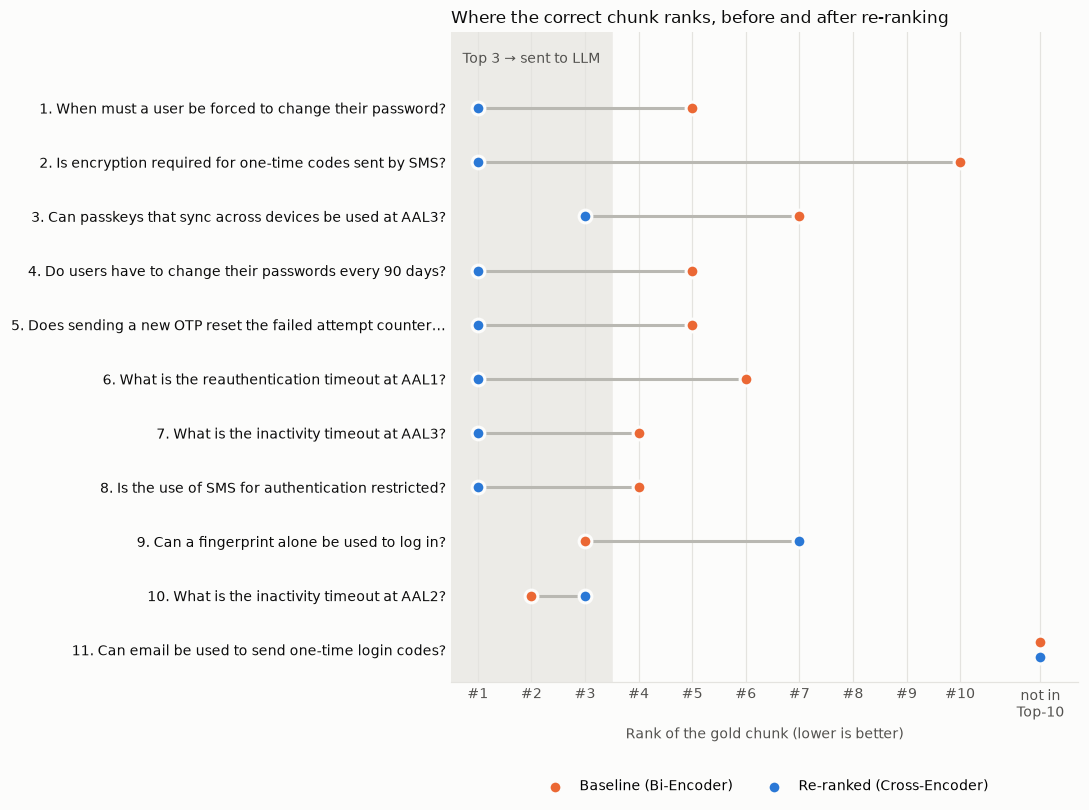

In [26]:
import matplotlib.pyplot as plt

# Colours: orange = baseline, blue = re-ranked; grey band = ranks that go to the LLM.
C_BASE, C_RERANK, INK, INK2, GRID = "#eb6834", "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df"
NOT_FOUND = 11.5                                           # x position used for "not in Top 10"

fig, ax = plt.subplots(figsize=(10, 0.55 * len(all_results) + 1.4), dpi=110)
fig.patch.set_facecolor("#fcfcfb"); ax.set_facecolor("#fcfcfb")
ax.axvspan(0.5, TOP_K_CONTEXT + 0.5, color="#ecebe7", zorder=0)
ax.text(2, -0.9, "Top 3 → sent to LLM", ha="center", va="center", fontsize=9, color=INK2)
for y, r in enumerate(all_results):
    b = r["base_rank"] or NOT_FOUND; n = r["rerank_rank"] or NOT_FOUND
    yb, yn = (y - 0.14, y + 0.14) if b == n else (y, y)     # same rank: draw the two dots a little apart
    ax.plot([b, n], [yb, yn], color="#b9b8b2", lw=2, zorder=1)
    ax.scatter(b, yb, s=70, color=C_BASE, zorder=3, edgecolors="#fcfcfb", linewidths=2, label="Baseline (Bi-Encoder)" if y == 0 else None)
    ax.scatter(n, yn, s=70, color=C_RERANK, zorder=3, edgecolors="#fcfcfb", linewidths=2, label="Re-ranked (Cross-Encoder)" if y == 0 else None)
ax.set_yticks(range(len(all_results)), [f"{r['case_no']}. {r['query'][:55]}{'…' if len(r['query']) > 55 else ''}" for r in all_results],
              fontsize=9, color=INK)
ax.set_xticks(list(range(1, 11)) + [NOT_FOUND], [f"#{i}" for i in range(1, 11)] + ["not in\nTop-10"], fontsize=9, color=INK2)
ax.set_xlim(0.5, 12.2); ax.set_ylim(len(all_results) - 0.4, -1.4)
ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True)
for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(GRID); ax.tick_params(length=0)
ax.set_xlabel("Rank of the gold chunk (lower is better)", color=INK2, fontsize=9)
ax.set_title("Where the correct chunk ranks, before and after re-ranking", loc="left", fontsize=11, color=INK)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, frameon=False, fontsize=9)
plt.tight_layout(); plt.savefig(RESULTS_DIR / "rank_shift.png", facecolor=fig.get_facecolor(), bbox_inches="tight"); plt.show()

## 9. Retrieval quality over a wider query set

The stress tests above are, by design, hard cases. To check that re-ranking helps *in general* and not only on hand-picked
queries, we run **retrieval only** (no LLM) on a broader set of questions covering the whole standard, each with its gold sentence.
The set contains **every question we tried while looking for failure cases**, including easy ones, ones where re-ranking hurt, and ones the Bi-Encoder missed entirely.
So it is not a cherry-picked list.

* **Hit@3** = fraction of queries whose gold chunk reaches the LLM (is in the Top 3).
* **MRR@10** = mean of 1/rank of the gold chunk (0 if not in Top 10).

In [27]:
EVAL_SET = [(c["query"], c["gold_phrase"]) for c in FAILURE_CASES + COUNTER_CASES] + [
    ("What is the minimum password length when the password is used together with a second factor?", "minimum of eight characters"),
    ("What is the minimum password length?", "minimum of 15 characters"),
    ("How long is a recovery code valid when sent by SMS?", "10 minutes when sent via text message"),
    ("How long is a recovery code mailed abroad valid?", "30 days when sent to a postal address outside"),
    ("When must notifications be sent to a postal address?", "notifications SHALL be sent to postal addresses if no other"),
    ("Can a remember-this-device cookie replace logging in?", "remember my browser"),
    ("Can a website require passwords to contain uppercase letters, digits and symbols?", "SHALL NOT impose other composition rules"),
    ("Can voice recognition be used for authentication?", "Biometric comparison based on voice SHALL NOT be used"),
    ("Are password hints allowed?", "store a hint"),
    ("Can security questions like the name of your first pet be used?", "knowledge-based authentication"),
    ("Should session tokens be stored in browser local storage?", "HTML5 Local Storage"),
    ("Can an authenticated session switch from https to http?", "fall back to an insecure transport"),
    ("Is an SMS one-time code phishing-resistant?", "manual entry of an authenticator output"),
    ("How often must a user re-authenticate at AAL3?", "overall timeout for reauthentication SHALL be no more than 12 hours"),
    ("What is the maximum session length at AAL2?", "no more than 24 hours at AAL2"),
    ("How many failed login attempts are allowed before the account is locked?", "to no more than 100 by disabling"),
    ("How many failed fingerprint attempts are allowed?", "no more than five consecutive failed authentication attempts"),
    ("How long must the salt be when hashing passwords?", "salt SHALL be at least 32 bits"),
    ("How long is an out-of-band code valid?", "invalid unless completed within 10 minutes"),
    ("What false match rate must a biometric system achieve?", "one in 10000"),
    ("What maximum password length should be allowed?", "maximum password length of at least 64"),
    ("What is the minimum length of a binding code?", "at least 40 bits"),
    ("How many notification addresses must be supported per account?", "at least two notification addresses"),
    ("What is the minimum length of a challenge nonce?", "challenge nonce SHALL be at least 64 bits"),
    ("Can users paste passwords from a password manager?", 'use the "paste" function'),
    ("Is a SIM swap a risk for SMS codes?", "SIM change, number porting"),
    ("Can one phone be registered as an authenticator by several users?", "registered as an authenticator by multiple subscribers"),
    ("Can an expired authenticator still be used?", "When an authenticator expires, it SHALL NOT be usable"),
    ("Is a fingerprint considered a secret?", "Biometric characteristics do not constitute secrets"),
    ("Must users be offered an option other than face recognition?", "authentication option SHALL always be provided"),
    ("Should session cookies be readable by JavaScript?", "HttpOnly"),
    ("Must AAL2 services offer a phishing-resistant option?", "SHALL offer at least one phishing-resistant authentication option at AAL2"),
    ("Can a session be treated as a higher AAL than the login that created it?", "SHALL NOT be considered at a higher AAL than the authentication event"),
    ("How short can an OTP be truncated?", "as few as six decimal digits"),
    ("Can the password be checked against a list of breached passwords?", "passwords from previous breach corpuses"),
    ("How long is a binding code valid?", "valid for a maximum of 10 minutes"),
    ("Should biometric data be deleted after authentication?", "SHALL be erased immediately after an authentication operation"),
]

eval_rows = []
for q, gold in EVAL_SET:
    golds = gold_chunks(gold)
    top10, _, _ = baseline_retrieve(q)
    reranked, _, _ = cross_encoder_rerank(q, top10)
    eval_rows.append({"query": q, "baseline_rank": best_rank(top10, golds), "rerank_rank": best_rank(reranked, golds)})
eval_df = pd.DataFrame(eval_rows)

def metrics(col):
    ranks = eval_df[col]
    return {"Hit@1": (ranks == 1).mean(), "Hit@3": (ranks <= 3).mean(), "Hit@10 (recall of stage 1)": ranks.notna().mean(),
            "MRR@10": ranks.map(lambda x: 1 / x if x == x and x else 0).mean()}

metrics_df = pd.DataFrame({"Pipeline 1 (Bi-Encoder)": metrics("baseline_rank"), "Pipeline 2 (+ Cross-Encoder)": metrics("rerank_rank")}).round(3)
both = eval_df.dropna()
print(f"{len(eval_df)} queries | gold rank improved: {(both.rerank_rank < both.baseline_rank).sum()}, "
      f"unchanged: {(both.rerank_rank == both.baseline_rank).sum()}, worsened: {(both.rerank_rank > both.baseline_rank).sum()}, "
      f"gold not in Top-10: {eval_df.baseline_rank.isna().sum()}")
eval_df.to_csv(RESULTS_DIR / "eval_ranks.csv", index=False); metrics_df.to_csv(RESULTS_DIR / "eval_metrics.csv")
display(metrics_df)

48 queries | gold rank improved: 19, unchanged: 15, worsened: 5, gold not in Top-10: 9


,Pipeline 1 (Bi-Encoder),Pipeline 2 (+ Cross-Encoder)
Hit@1,0.250,0.500
Hit@3,0.583,0.750
Hit@10 (recall of stage 1),0.812,0.812
MRR@10,0.437,0.617


**Observation.** Across **48 questions** (every question we tried, including the counter-examples), re-ranking doubles **Hit@1 (0.25 → 0.50)**, raises **Hit@3 from 0.58 to 0.75** and **MRR@10 from 0.44 to 0.62**.
The gold chunk moves up in 19 queries, stays put in 15 and moves down in 5. In 3 of those 5 it stays inside the Top 3, and in 2 it drops out (“Can a fingerprint alone be used to log in?” #3 → #7; “Can the password be checked against a list of breached passwords?” #3 → #4).
**9 of 48 gold chunks (19 %) never reach the Top 10**, so for them neither pipeline can succeed. Five of these nine gold sentences are SHALL NOT rules (composition rules, password hints, voice biometrics, email for OOB, manual entry codes not being phishing resistant).
In this 413-chunk document the **recall of stage 1, not the ordering, is the main remaining weakness**.
*Caveat:* these are questions we wrote ourselves, so the numbers are indicative, not a benchmark.

### 9.1 Robustness check: does the result depend on the chunk size?

The chunk size changes which chunks exist, so it can change which queries fail. We repeat the retrieval-only evaluation with two other chunkings
(same models, same questions; each chunking gets its own index). *Note:* the stress-test queries were found with 120-word chunks, so the 120-word row is slightly favoured.

In [28]:
def evaluate_chunking(size, overlap):
    # Build chunks and an index for this chunk size, then measure Hit@3 and MRR@10 for both pipelines (retrieval only).
    ch = make_chunks(words, word_page, size, overlap)["text"].tolist()
    emb = bi_encoder.encode(ch, normalize_embeddings=True, convert_to_numpy=True, batch_size=32).astype("float32")
    idx = faiss.IndexFlatIP(emb.shape[1]); idx.add(emb)
    b_ranks, r_ranks = [], []
    for q, gold in EVAL_SET:
        phrases = [gold] if isinstance(gold, str) else gold
        golds = [i for i, c in enumerate(ch) if any(norm(p) in norm(c) for p in phrases)]
        _, ids = idx.search(bi_encoder.encode([q], normalize_embeddings=True, convert_to_numpy=True).astype("float32"), TOP_K_RETRIEVE)
        top10 = ids[0].tolist()
        s = cross_encoder.predict([(q, ch[c]) for c in top10])
        b_ranks.append(best_rank(top10, golds)); r_ranks.append(best_rank([top10[i] for i in np.argsort(-s)], golds))
    hit3 = lambda rs: np.mean([bool(r and r <= 3) for r in rs]); mrr = lambda rs: np.mean([1 / r if r else 0 for r in rs])
    return {"chunks": len(ch), "Hit@3 P1": hit3(b_ranks), "Hit@3 P2": hit3(r_ranks), "MRR@10 P1": mrr(b_ranks), "MRR@10 P2": mrr(r_ranks)}

robustness = pd.DataFrame({f"{s} words / {o} overlap": evaluate_chunking(s, o) for s, o in [(100, 25), (120, 30), (150, 40)]}).T.round(3)
robustness["chunks"] = robustness["chunks"].astype(int)
robustness.to_csv(RESULTS_DIR / "chunk_size_robustness.csv")
display(robustness)

,chunks,Hit@3 P1,Hit@3 P2,MRR@10 P1,MRR@10 P2
100 words / 25 overlap,495,0.542,0.688,0.372,0.570
120 words / 30 overlap,413,0.583,0.750,0.437,0.617
150 words / 40 overlap,338,0.583,0.708,0.450,0.639


**Observation.** Re-ranking improves Hit@3 and MRR@10 at **every** chunk size: Hit@3 rises by +0.15 (100 words), +0.17 (120 words) and +0.13 (150 words), and MRR rises by about +0.18 to +0.20 in each case.
The conclusion therefore does not depend on the 120-word choice. Smaller chunks give the lowest absolute scores, because a rule and its context are split more often, but the gap between the pipelines stays similar.

## 10. Latency profiling

For every stress-test query we time each stage **20 times** (after a warm-up call) and report the mean, median and 95th percentile.

* **Pipeline 1 retrieval** = embed the query with the Bi-Encoder + FAISS search over all chunks.
* **Pipeline 2 retrieval** = Pipeline 1 retrieval **+** Cross-Encoder scoring of the 10 candidates + sort.
* **LLM generation** is timed once per answer (from section 7). It is the same model and prompt length for both pipelines, so it adds about the same time to each.

Hardware: the CPU this notebook was executed on (no GPU).

In [29]:
N_REPEATS = 20
queries = [r["query"] for r in all_results]
baseline_retrieve(queries[0]); cross_encoder_rerank(queries[0], list(range(10)))     # warm up (the first call is slower)

t_ret, t_rr = [], []
for q in queries:
    for _ in range(N_REPEATS):
        top10, _, a = baseline_retrieve(q)
        _, _, b = cross_encoder_rerank(q, top10)
        t_ret.append(a * 1000); t_rr.append(b * 1000)
t_p2 = [a + b for a, b in zip(t_ret, t_rr)]
llm1 = [r["t_llm1"] * 1000 for r in all_results]; llm2 = [r["t_llm2"] * 1000 for r in all_results]

def stats(xs):
    return {"mean_ms": np.mean(xs), "median_ms": np.median(xs), "p95_ms": np.percentile(xs, 95)}

latency = pd.DataFrame({
    "Pipeline 1: Bi-Encoder retrieval (query embed + top-10 search)": stats(t_ret),
    "Pipeline 2: extra Cross-Encoder re-rank (10 pairs)":              stats(t_rr),
    "Pipeline 2: total retrieval (retrieve + re-rank)":                stats(t_p2),
    "LLM generation, Answer 1":                                        stats(llm1),
    "LLM generation, Answer 2":                                        stats(llm2),
    "End-to-end Pipeline 1 (retrieval + LLM)":                         stats(np.mean(t_ret) + np.array(llm1)),
    "End-to-end Pipeline 2 (retrieval + re-rank + LLM)":               stats(np.mean(t_p2) + np.array(llm2)),
}).T.round(1)
latency.to_csv(RESULTS_DIR / "latency.csv")
print(f"{len(queries)} queries × {N_REPEATS} repeats | LLM: {LLM_NAME}")
e2e1, e2e2 = np.mean(t_ret) + np.mean(llm1), np.mean(t_p2) + np.mean(llm2)
print(f"Re-ranking makes retrieval {np.mean(t_p2) / np.mean(t_ret):.1f}× slower "
      f"(+{np.mean(t_rr):.1f} ms per query), which is {100 * np.mean(t_rr) / np.mean(llm1):.1f}% of the baseline LLM generation time.")
print(f"Measured end-to-end time: {e2e1 / 1000:.2f} s -> {e2e2 / 1000:.2f} s ({100 * (e2e2 / e2e1 - 1):+.1f}%). "
      "This also contains run-to-run variation of the LLM, so it is not caused by re-ranking alone.")
display(latency)

11 queries × 20 repeats | LLM: Qwen/Qwen2.5-1.5B-Instruct
Re-ranking makes retrieval 21.5× slower (+365.7 ms per query), which is 0.7% of the baseline LLM generation time.
Measured end-to-end time: 51.02 s -> 52.08 s (+2.1%). This also contains run-to-run variation of the LLM, so it is not caused by re-ranking alone.


,mean_ms,median_ms,p95_ms
Pipeline 1: Bi-Encoder retrieval (query embed + top-10 search),17.8,17.5,23.2
Pipeline 2: extra Cross-Encoder re-rank (10 pairs),365.7,350.4,489.2
Pipeline 2: total retrieval (retrieve + re-rank),383.5,368.1,509.4
"LLM generation, Answer 1",51000.6,50487.6,60171.0
"LLM generation, Answer 2",51698.1,51869.9,56433.8
End-to-end Pipeline 1 (retrieval + LLM),51018.3,50505.4,60188.8
End-to-end Pipeline 2 (retrieval + re-rank + LLM),52081.6,52253.4,56817.3


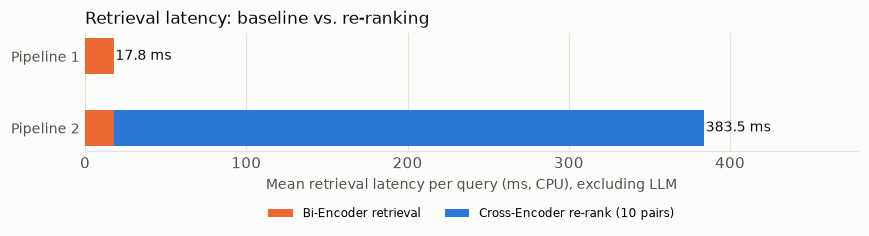

In [30]:
fig, ax = plt.subplots(figsize=(8, 2.6), dpi=110)
fig.patch.set_facecolor("#fcfcfb"); ax.set_facecolor("#fcfcfb")
m_ret, m_rr = np.mean(t_ret), np.mean(t_rr)
ax.barh(1, m_ret, height=0.5, color=C_BASE, label="Bi-Encoder retrieval")
ax.barh(0, m_ret, height=0.5, color=C_BASE)
ax.barh(0, m_rr, left=m_ret + 0.4, height=0.5, color=C_RERANK, label="Cross-Encoder re-rank (10 pairs)")
ax.text(m_ret + 1, 1, f"{m_ret:.1f} ms", va="center", fontsize=9, color=INK)
ax.text(m_ret + m_rr + 1.4, 0, f"{m_ret + m_rr:.1f} ms", va="center", fontsize=9, color=INK)
ax.set_yticks([1, 0], ["Pipeline 1", "Pipeline 2"], fontsize=9, color=INK)
ax.set_xlim(0, (m_ret + m_rr) * 1.25)
ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True)
for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(GRID); ax.tick_params(length=0, labelcolor=INK2)
ax.set_xlabel("Mean retrieval latency per query (ms, CPU), excluding LLM", color=INK2, fontsize=9)
ax.set_title("Retrieval latency: baseline vs. re-ranking", loc="left", fontsize=11, color=INK)
ax.legend(loc="upper center", frameon=False, fontsize=8, ncol=2, bbox_to_anchor=(0.5, -0.38))
plt.tight_layout(); plt.savefig(RESULTS_DIR / "latency.png", facecolor=fig.get_facecolor(), bbox_inches="tight"); plt.show()

### 10.1 Scaling experiment: why not run the Cross-Encoder over the whole collection?

We measure the alternative directly: score **every** chunk of the document with the Cross-Encoder (no Bi-Encoder stage) and compare with
dense search over the same chunks. Then we extrapolate the measured per-pair cost to larger collections.
The Bi-Encoder side scales differently: chunk embeddings are computed **once, offline**, and at query time only one query embedding + a vector search is needed
(with an approximate index such as HNSW/IVF this search stays in the millisecond range even for millions of vectors).

In [31]:
q = queries[0]
all_ids = list(range(len(chunks)))
cross_encoder_rerank(q, all_ids)                                         # warm up
t_full = [cross_encoder_rerank(q, all_ids)[2] * 1000 for _ in range(3)]
per_pair_ms = np.mean(t_full) / len(chunks)

full_ranked, _, _ = cross_encoder_rerank(q, all_ids)
golds = gold_chunks(FAILURE_CASES[0]["gold_phrase"])
print(f"Cross-Encoder over ALL {len(chunks)} chunks: {np.mean(t_full):.0f} ms per query ({per_pair_ms:.2f} ms per pair) "
      f"vs. Bi-Encoder retrieval {np.mean(t_ret):.1f} ms and two-stage {np.mean(t_p2):.1f} ms")
print(f"Gold chunk rank with full Cross-Encoder scan: #{best_rank(full_ranked, golds)} (two-stage gave #{all_results[0]['rerank_rank']})")

scaling = pd.DataFrame({"collection size (chunks)": [len(chunks), 10_000, 1_000_000, 100_000_000]})
scaling["Cross-Encoder on every chunk (est.)"] = (scaling.iloc[:, 0] * per_pair_ms / 1000).map(
    lambda s: f"{s:,.1f} s" if s < 3600 else f"{s / 3600:,.1f} hours")
scaling["Two-stage: Cross-Encoder on 10 candidates"] = f"{np.mean(t_rr):.0f} ms (constant)"
scaling["Cross-Encoder pairs per query"] = scaling.iloc[:, 0].map(lambda n: f"{n:,}")
scaling.to_csv(RESULTS_DIR / "scaling.csv", index=False)
display(scaling)

Cross-Encoder over ALL 413 chunks: 16870 ms per query (40.85 ms per pair) vs. Bi-Encoder retrieval 17.8 ms and two-stage 383.5 ms
Gold chunk rank with full Cross-Encoder scan: #1 (two-stage gave #1)


,collection size (chunks),Cross-Encoder on every chunk (est.),Two-stage: Cross-Encoder on 10 candidates,Cross-Encoder pairs per query
0,413,16.9 s,366 ms (constant),413
1,10000,408.5 s,366 ms (constant),"10,000"
2,1000000,11.3 hours,366 ms (constant),"1,000,000"
3,100000000,"1,134.6 hours",366 ms (constant),"100,000,000"


**Observation.**
* Re-ranking makes **retrieval ~21× slower**: about 18 ms for Bi-Encoder retrieval vs. about 384 ms with the Cross-Encoder (≈ 37 ms per (query, chunk) pair on this CPU).
* **End to end:** re-ranking adds about 366 ms per query, which is under 1 % of the baseline LLM generation time (about 51 s). The *measured* end-to-end time rose from 51.02 s to 52.08 s (+2.1 %). That difference also contains run-to-run variation of the LLM (the two LLM rows differ by 0.7 s), so it should not be attributed entirely to re-ranking.
* **Scaling:** scoring *all* 413 chunks with the Cross-Encoder takes about **16.9 s per query**, **44× slower** than the two-stage pipeline, and for this query it returns the same #1 chunk.
  The cost grows linearly with collection size (≈ 11 hours per query for 1M chunks on this CPU), because every (query, chunk) pair needs its own transformer forward pass and nothing can be pre-computed.
  The Bi-Encoder pays its per-chunk cost **once, offline** (13.5 s to embed all 413 chunks here). At query time it embeds only the query and runs a vector search, which an ANN index keeps fast even for millions of vectors.
  A GPU would lower the absolute numbers but not the linear growth.

## 11. Where to find the evidence for each report question

| Report question | Evidence in this notebook |
|---|---|
| 1. Architecture comparison (Bi-Encoder vs Cross-Encoder) | §4.1 and §4.2 (how each model is called: independent `encode()` + cosine vs. joint `predict((query, chunk))`); §10.1 (consequence for cost) |
| 2. Rank shifts & Answer 1 vs Answer 2 | §7.1-7.9 (per-query tables, answers and observations), §8 (summary table + chart, `results/rank_shift_summary.csv`), §9 (Hit@3 / MRR, chunk-size robustness) |
| 3. Latency profiling | §10 table + chart (`results/latency.csv`) |
| 4. Scaling question | §10.1 measured full-corpus Cross-Encoder cost and extrapolation (`results/scaling.csv`) |

All result tables and figures are also saved in the `results/` folder.